# Electric cooking on solar mini-grids in Rwanda and Kenya

**Research notebook** · Abubakar Chilala

This notebook walks through the study from its input data to its main results. It runs the model code in `src/` rather than only reading saved numbers, and checks that the live results match the files in `results/`.

**Question.** What happens to a solar mini-grid, and to the homes it serves, when homes cook with a 1 kW electric pressure cooker? We measure three things:

1. the cost per kWh (levelised cost of electricity, LCOE);
2. the price households pay under national tariffs;
3. the operating subsidy the operator needs, and the part of it caused by cooking.

**Sites.** Two model villages of 300 homes: Nkombo Island (Lake Kivu, Rwanda) and Ringiti Island (Lake Victoria, Kenya).

**Contents**

1. Data: household surveys, cooking times, weather, tariffs and costs
2. Demand model and its calibration
3. Hourly operation and least-cost sizing
4. Cost, price and subsidy
5. Household-level analytics
6. Weather-year analytics
7. Uncertainty
8. Headline numbers and how to reproduce everything

**How to run.** Use Python 3.11 with `requirements.txt` (the RAMP package needs numpy below 2). Open the notebook from the repository root or from `notebooks/`. On the first run the hourly NASA POWER weather (two sites, 2005 to 2024) is downloaded if it is not already in `data/processed/`; this needs internet access and takes about 80 seconds. After that the whole notebook runs in about two minutes.

**Data licence.** The Rwanda Multi-Tier Framework (MTF) 2022 microdata are licensed and are not in this repository. The notebook uses only the derived aggregates in `data/processed/`. Re-deriving those aggregates needs the microdata in `data/raw/` (see `python src/pipeline.py mtf`).

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path

# find the repository root, so the notebook runs from the root or from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "params.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook inside the EDA repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)                      # the model reads data/ paths relative to the root
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e2dd",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False})

SITES = ("rwanda", "kenya")
NAME = {"rwanda": "Rwanda (Nkombo)", "kenya": "Kenya (Ringiti)"}
COL = {"rwanda": "#2a78d6", "kenya": "#eb6834"}
P, R = ROOT / "data" / "processed", ROOT / "results"
PARAMS = yaml.safe_load(open("params.yaml"))
N_HOMES, SEED = PARAMS["run"]["connections"], PARAMS["run"]["seed"]
print("repository:", ROOT)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

repository: /home/user/EDA
python 3.11.18 | numpy 1.26.4 | pandas 2.1.4


In [2]:
# Hourly weather: about 8 MB per site, not stored in git. Download once if missing.
missing = [s for s in SITES if not (P / f"resource_{s}.csv").exists()]
if missing:
    print("Downloading hourly NASA POWER weather for", missing, "(needs internet, about 80 s)")
    subprocess.run([sys.executable, "src/pipeline.py", "resource"], check=True)
print("hourly weather files present:", all((P / f"resource_{s}.csv").exists() for s in SITES))

hourly weather files present: True


In [3]:
# Model code (src/)
from final_cfg import country_cfg
from run_scenarios import make_load_builder
from solar_resource import load_site_resource, resource_years
from load_builder import CookingParams, build_cooking_load, diversity_factor
from validate_cooking import calibrate_timing_sd
from model import Battery, _pv_dc, dispatch_year, simulate
from expansion import size_design
from operating_subsidy import annuity_factor, by_adoption
from household_bands import bill, household_monthly
from interannual import by_weather_year
from manuscript_tables import build_all

CFG = {s: country_cfg(s) for s in SITES}
DESIGN_YEAR = {s: PARAMS["countries"][s]["design_year"] for s in SITES}
MEDIAN_YEAR = {s: PARAMS["countries"][s]["representative_year"] for s in SITES}
print("design (hardest) weather year:", DESIGN_YEAR)
print("median weather year:          ", MEDIAN_YEAR)

design (hardest) weather year: {'rwanda': 2011, 'kenya': 2022}
median weather year:           {'rwanda': 2015, 'kenya': 2007}


## 1. Data

### 1.1 Household surveys: who owns what

Appliance ownership comes from the World Bank Multi-Tier Framework surveys of Rwanda (2022) and Kenya (2016 to 2018). Each survey is filtered to **rural homes with a grid connection**, the group a new mini-grid customer is most likely to resemble. The share of homes owning appliance $j$ is the survey-weighted mean

$$\hat p_j=\frac{\sum_i w_i\,\mathbf{1}[\text{home } i \text{ owns } j]}{\sum_i w_i},$$

with survey weight $w_i$ and all homes in the denominator. Wattage and hours of use are recorded by neither survey, so they are set to the same values in both countries: the countries differ only in measured ownership, weather and tariff.

In [4]:
own = pd.read_csv(P / "appliance_ownership_both.csv")
n = own.groupby("country").n_households.first()
print(f"Rwanda: {n['rwanda']:,} of {int(own[own.country == 'rwanda'].n_before_filters.iloc[0]):,} surveyed homes kept "
      f"(rural, grid-connected) | Kenya: {n['kenya']:,} rural grid-connected homes")

# the shares the model uses (src/final_cfg.py): Kenya from the core survey question
ks = pd.read_csv(P / "appliance_ownership_kenya_sources.csv").set_index("appliance")
share = pd.DataFrame({"Rwanda, %": {k: 100 * v[0] for k, v in CFG["rwanda"]["appliances"].items()},
                      "Kenya (core question), %": {k: 100 * v[0] for k, v in CFG["kenya"]["appliances"].items()},
                      "Kenya (asset roster), %": 100 * ks["M3 asset flags"]})
share.sort_values("Rwanda, %", ascending=False).round(1)

Rwanda: 1,115 of 5,706 surveyed homes kept (rural, grid-connected) | Kenya: 521 rural grid-connected homes


,"Rwanda, %","Kenya (core question), %","Kenya (asset roster), %"
mobile_charger,71.5,19.6,3.9
cfl_bulb,54.1,11.6,2.0
incandescent_bulb,38.1,25.6,8.3
torch_lantern,23.6,7.5,2.5
radio_cd_system,19.7,NaN,NaN
smartphone_charger,16.8,15.8,3.2
radio,14.8,39.3,6.8
led_bulb,10.6,10.6,1.8
tv_colour,6.9,34.8,9.6
electric_iron,6.8,12.0,3.5


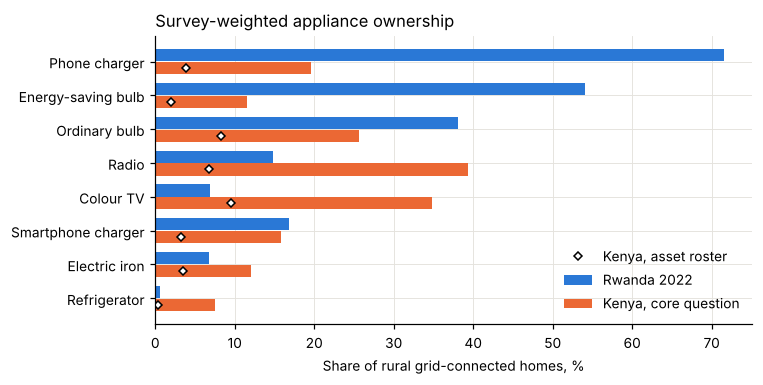

Kenya: the core question reports 2.8 to 5.8 times the ownership of the asset roster for appliances owned by at least 10% of homes.


In [5]:
LABEL = {"mobile_charger": "Phone charger", "cfl_bulb": "Energy-saving bulb",
         "incandescent_bulb": "Ordinary bulb", "radio": "Radio", "radio_cd_system": "Radio",
         "tv_colour": "Colour TV", "smartphone_charger": "Smartphone charger",
         "electric_iron": "Electric iron", "refrigerator": "Refrigerator"}
rw = own[own.country == "rwanda"].set_index("appliance").ownership_rate
items = [k for k in ["mobile_charger", "cfl_bulb", "incandescent_bulb", "radio", "tv_colour",
                     "smartphone_charger", "electric_iron", "refrigerator"] if k in ks.index]

fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(items))[::-1]
ax.barh(y + 0.19, [100 * rw.get(k, 0) for k in items], 0.36, color=COL["rwanda"], label="Rwanda 2022")
ax.barh(y - 0.19, [100 * ks.loc[k, "core m_m_3_group"] for k in items], 0.36, color=COL["kenya"],
        label="Kenya, core question")
ax.plot([100 * ks.loc[k, "M3 asset flags"] for k in items], y - 0.19, "D", ms=4, mfc="white",
        mec="black", ls="none", label="Kenya, asset roster")
ax.set_yticks(y, [LABEL.get(k, k) for k in items])
ax.set_xlabel("Share of rural grid-connected homes, %")
ax.set_title("Survey-weighted appliance ownership", loc="left")
ax.legend(loc="lower right")
plt.show()

common = ks[ks["core m_m_3_group"] >= 0.10]
ratio = common["core m_m_3_group"] / common["M3 asset flags"]
print(f"Kenya: the core question reports {ratio.min():.1f} to {ratio.max():.1f} times the ownership "
      f"of the asset roster for appliances owned by at least 10% of homes.")

The Kenyan survey asks about appliances twice, and the two questions disagree. The core question is used because its phone-charger ownership (about 20%) is far more plausible than the roster's (about 4%). Section 7 shows what the roster would change.

### 1.2 When homes cook

The shares of cooking time in the morning, afternoon and evening come from the Kenyan survey. The base case uses rural homes without grid access, the group closest to future cooking customers.

,n,"morning, %","afternoon, %","evening, %"
group,,,,
Rural with grid access,445,27.0,32.0,41.0
Rural without grid access,1771,27.5,33.1,39.5
Urban with grid access,1295,26.2,28.7,45.2
Urban without grid access,416,28.4,31.0,40.6
ALL,3927,27.1,31.4,41.4


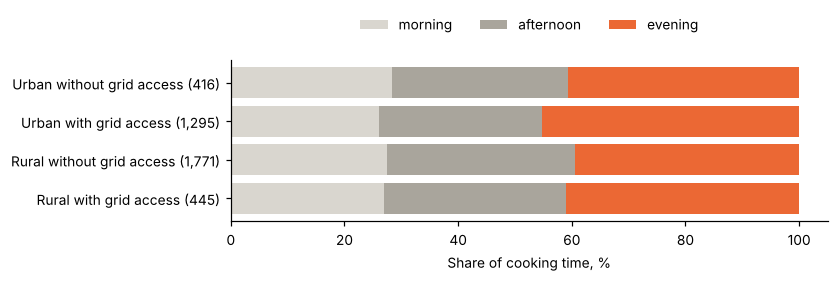

Evening share of cooking time across Kenyan groups: 39 to 45%. Rwanda: 82.5% of rural homes collect firewood at no cash cost.


In [6]:
dp = pd.read_csv(P / "cooking_dayparts_kenya.csv").set_index("group")
show = dp[["n", "share_morning", "share_afternoon", "share_evening"]].copy()
show[["share_morning", "share_afternoon", "share_evening"]] *= 100
display(show.round(1).rename(columns=lambda c: c.replace("share_", "") + (", %" if c != "n" else "")))

g = dp.drop(index="ALL")
fig, ax = plt.subplots(figsize=(7, 1.9))
left = np.zeros(len(g))
for c, col in (("share_morning", "#d9d6cf"), ("share_afternoon", "#a9a59c"), ("share_evening", COL["kenya"])):
    ax.barh(range(len(g)), 100 * g[c], left=left, color=col, label=c.replace("share_", ""))
    left += 100 * g[c].values
ax.set_yticks(range(len(g)), [f"{i} ({n:,})" for i, n in zip(g.index, g.n)])
ax.set_xlabel("Share of cooking time, %")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.35))
ax.grid(False)
plt.show()

fu = pd.read_csv(P / "fuel_use_rwanda.csv")
wood = fu[(fu.scope == "rural") & (fu.fuel_code == 3)].share_using.iloc[0]
print(f"Evening share of cooking time across Kenyan groups: {100 * g.share_evening.min():.0f} to "
      f"{100 * g.share_evening.max():.0f}%. Rwanda: {100 * wood:.1f}% of rural homes collect firewood at no cash cost.")

About 40% of cooking time falls in the evening, after sunset, in every group. That energy must come from the battery, which is why meal timing matters for the size and cost of the system.

### 1.3 Weather

Hourly global horizontal irradiance $G$ and air temperature $T_a$ come from NASA POWER for 2005 to 2024 at each island. Each system is sized on its site's hardest weather year.

hours per year: [8760, 8784]


,Rwanda (Nkombo),Kenya (Ringiti)
"median, kWh/m2","1,744","2,076"
"range, kWh/m2","1,691 to 1,820","1,977 to 2,144"
"brightest minus darkest, % of median",7.4,8.0
darkest year,2022,2022
design (hardest) year,2011,2022


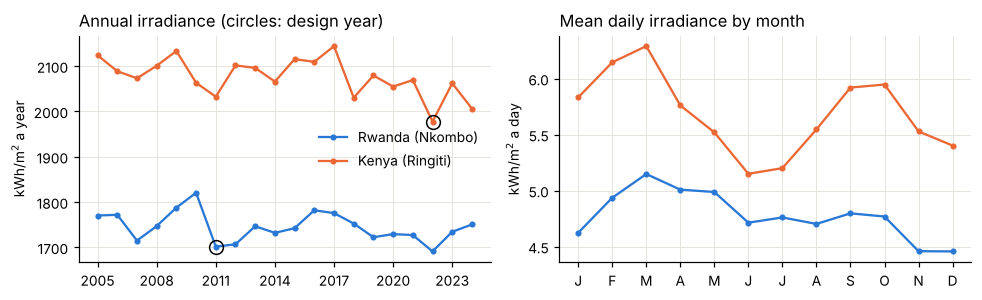

In [7]:
YEARS = {s: resource_years(s) for s in SITES}
rs = pd.read_csv(P / "resource_summary.csv")
annual = rs.pivot(index="year", columns="site", values="ghi_kwh_m2_yr")
print("hours per year:", sorted(rs.hours.unique()))
summary = pd.DataFrame({NAME[s]: {"median, kWh/m2": f"{annual[s].median():,.0f}",
                                  "range, kWh/m2": f"{annual[s].min():,.0f} to {annual[s].max():,.0f}",
                                  "brightest minus darkest, % of median": f"{100 * (annual[s].max() - annual[s].min()) / annual[s].median():.1f}",
                                  "darkest year": int(annual[s].idxmin()), "design (hardest) year": DESIGN_YEAR[s]}
                        for s in SITES})
display(summary)

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 2.8))
for s in SITES:
    a.plot(annual.index, annual[s], "o-", ms=3, color=COL[s], label=NAME[s])
    a.plot(DESIGN_YEAR[s], annual.loc[DESIGN_YEAR[s], s], "o", ms=9, mfc="none", mec="black")
    # mean daily irradiance by month, all 20 years
    d = pd.concat([pd.Series(np.asarray(r["ghi"])[:8760].reshape(365, 24).sum(1) / 1000) for r in YEARS[s].values()], axis=1).mean(1)
    month = pd.date_range("2021-01-01", periods=365, freq="D").month
    b.plot(range(1, 13), d.groupby(month).mean().values, "o-", ms=3, color=COL[s], label=NAME[s])
a.set_title("Annual irradiance (circles: design year)", loc="left")
a.set_xticks(range(2005, 2025, 3))
a.set_ylabel("kWh/m$^2$ a year")
a.legend()
b.set_title("Mean daily irradiance by month", loc="left")
b.set_ylabel("kWh/m$^2$ a day")
b.set_xticks(range(1, 13), list("JFMAMJJASOND"))
plt.tight_layout()
plt.show()

### 1.4 Tariffs and cost inputs

Both countries charge households more per kWh as monthly use rises. Rwanda's tariff is telescopic: the first 20 kWh of a month are cheap and only the units above cost more. Kenya's is a band tariff: once a home uses more than 30 kWh in a month, every unit of that month is charged at the higher rate. 90% of bills are collected.

In [8]:
rows = []
for s in SITES:
    t = CFG[s]["tariff"]
    lo = 0
    for hi, rate in t["bands"]:
        rows.append({"site": NAME[s], "band, kWh/month": f"{lo} to {hi if hi < 1e8 else 'above'}",
                     "US$/kWh": rate, "telescopic": t["telescopic"]})
        lo = hi
display(pd.DataFrame(rows))

c = CFG["rwanda"]
inputs = {"Solar, US$/kW": c["capex"]["pv_per_kw"], "Battery, US$/kWh": c["capex"]["battery_per_kwh"],
          "Inverter, US$/kW": c["capex"]["inverter_per_kw"], "Connection, US$/home": c["capex"]["connection_per_customer"],
          "Soft costs, share of hardware": c["capex"]["soft_cost_fraction"],
          "Service cost, US$/home/year": c["opex"]["per_customer_year"],
          "Plant upkeep, share of capex/year": c["opex"]["plant_fraction_per_year"],
          "Real discount rate": c["finance"]["discount_rate_real"], "Project life, years": c["finance"]["project_life_years"],
          "Battery usable share": c["battery"]["depth_of_discharge"], "Battery round-trip efficiency": c["battery"]["round_trip_efficiency"],
          "Unserved demand allowed, every year": c["reliability"]["max_unmet_demand_fraction"],
          "Appliance demand growth, per year": c["demand"]["annual_growth_rate"]}
pd.Series(inputs, name="value (both sites)").to_frame()

,site,"band, kWh/month",US$/kWh,telescopic
0,Rwanda (Nkombo),0 to 20,0.061,True
1,Rwanda (Nkombo),20 to 50,0.212,True
2,Rwanda (Nkombo),50 to above,0.253,True
3,Kenya (Ringiti),0 to 30,0.094,False
4,Kenya (Ringiti),30 to 100,0.128,False
5,Kenya (Ringiti),100 to above,0.144,False


,value (both sites)
"Solar, US$/kW",1228.000
"Battery, US$/kWh",300.000
"Inverter, US$/kW",400.000
"Connection, US$/home",400.000
"Soft costs, share of hardware",0.333
"Service cost, US$/home/year",60.000
"Plant upkeep, share of capex/year",0.020
Real discount rate,0.120
"Project life, years",20.000
Battery usable share,0.800


## 2. Demand model and its calibration

### 2.1 Appliances and meals

Appliance demand is simulated with RAMP from the ownership shares. Cooking is simulated meal by meal: 2.5 meals a day per cooking home, assigned to the three parts of the day in the survey shares, with start times drawn around 07:00, 13:00 and 20:00 with spread $\sigma$. A meal's energy $e$ is drawn from a gamma distribution (mean 0.35 kWh), and the 1 kW cooker runs for at least 20 minutes:

$$E_{meal}=\max(e,\;P_c\,t_{min}),\qquad \bar E_{meal}\approx 0.40\ \text{kWh}.$$

CookingParams(meals_per_day=2.5, kwh_per_meal_mean=0.35, kwh_per_meal_cv=0.43, epc_power_kw=1.0, min_event_minutes=20, mealtime_centres_h={'morning': 7.0, 'afternoon': 13.0, 'evening': 20.0}, timing_sd_h=1.716, shifted_centre_h=15.0, shifted_window=(14, 16), thermal_retention_hours=5)


built 4 village loads in 2 s


,Rwanda (Nkombo),Kenya (Ringiti)
"kWh/home/month, no cooking",6.3,12.2
"kWh/home/month, all cook",36.8,42.6
"peak of average day, kW (all cook)",39.8,44.8


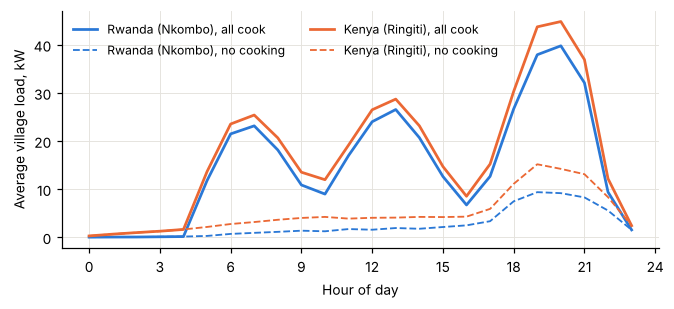

In [9]:
print(CookingParams())
t0 = time.time()
LOADS = {}
for s in SITES:
    for pen in (0.0, 1.0):
        b = make_load_builder(CFG[s], N_HOMES, pen, 0.0, SEED)
        LOADS[s, pen] = np.asarray(b(1), dtype=float)          # village load, kW, year 1
print(f"built 4 village loads in {time.time() - t0:.0f} s")

tab = pd.DataFrame({NAME[s]: {"kWh/home/month, no cooking": LOADS[s, 0.0].sum() / N_HOMES / 12,
                              "kWh/home/month, all cook": LOADS[s, 1.0].sum() / N_HOMES / 12,
                              "peak of average day, kW (all cook)": LOADS[s, 1.0].reshape(365, 24).mean(0).max()}
                    for s in SITES})
display(tab.round(1))

fig, ax = plt.subplots(figsize=(7, 2.8))
for s in SITES:
    ax.plot(range(24), LOADS[s, 1.0].reshape(365, 24).mean(0), color=COL[s], lw=1.8, label=f"{NAME[s]}, all cook")
    ax.plot(range(24), LOADS[s, 0.0].reshape(365, 24).mean(0), color=COL[s], lw=1.2, ls="--", label=f"{NAME[s]}, no cooking")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average village load, kW")
ax.set_xticks(range(0, 25, 3))
ax.legend(ncol=2, fontsize=8)
plt.show()

### 2.2 Calibrating the spread of meal times

The spread $\sigma$ is not observed in surveys, so it is fitted. For $n$ cooking homes with cookers of rating $P_c$, the diversity factor is

$$DF=\frac{n\,P_c}{\max_h \bar L(h)},$$

where $\bar L(h)$ is the average cooking load in hour $h$. Wider timing flattens the peak, so $DF$ rises with $\sigma$. We choose $\sigma$ by bisection so that the mean $DF$ over 10 random runs equals the 9.75 measured on Kenyan electric cookers (Scott et al., 2025). This is the only fitted parameter.

calibrated spread sigma = 1.716 h, mean DF = 9.74 (target 9.75)


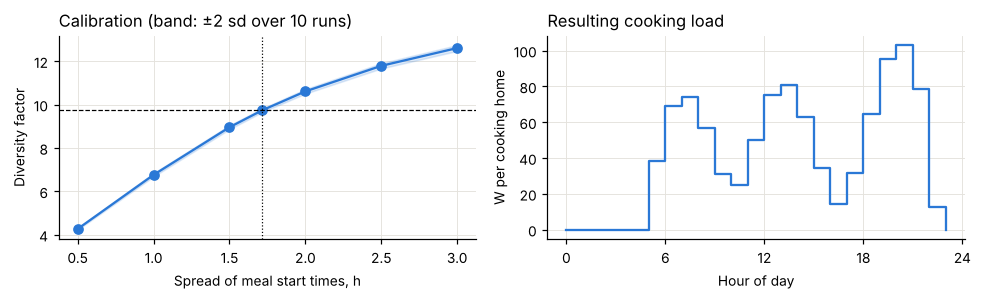

In [10]:
curve = []
for sd in [0.5, 1.0, 1.5, 1.716, 2.0, 2.5, 3.0]:
    p = CookingParams(timing_sd_h=sd)
    dfs = [diversity_factor(build_cooking_load(N_HOMES, 1.0, 0.0, p, seed=k), N_HOMES, 1.0) for k in range(10)]
    curve.append({"sigma_h": sd, "DF_mean": np.mean(dfs), "DF_sd": np.std(dfs, ddof=1)})
curve = pd.DataFrame(curve)

sigma, df_fit = calibrate_timing_sd()          # bisection on [0.5, 3.0] h, 10 seeds per step
print(f"calibrated spread sigma = {sigma:.3f} h, mean DF = {df_fit:.2f} (target 9.75)")

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 2.8))
a.plot(curve.sigma_h, curve.DF_mean, "o-", color="#2a78d6")
a.fill_between(curve.sigma_h, curve.DF_mean - 2 * curve.DF_sd, curve.DF_mean + 2 * curve.DF_sd, color="#2a78d6", alpha=0.15)
a.axhline(9.75, color="black", ls="--", lw=0.8)
a.axvline(sigma, color="black", ls=":", lw=0.8)
a.set_xlabel("Spread of meal start times, h")
a.set_ylabel("Diversity factor")
a.set_title("Calibration (band: ±2 sd over 10 runs)", loc="left")
cook = build_cooking_load(N_HOMES, 1.0, 0.0, CookingParams(), seed=0)
b.step(range(24), 1000 * cook.reshape(365, 24).mean(0) / N_HOMES, where="post", color="#2a78d6")
b.set_xlabel("Hour of day")
b.set_ylabel("W per cooking home")
b.set_xticks(range(0, 25, 6))
b.set_title("Resulting cooking load", loc="left")
plt.tight_layout()
plt.show()

### 2.3 Checks against data the model did not use

Only the diversity factor was fitted. The other rows below test the model against independent data: metered cooking energy, Kenya Power billing records and the size of the existing Ringiti plant.

In [11]:
v = pd.read_csv(R / "cooking_validation_summary.csv")
rb = pd.read_csv(R / "ringiti_benchmark.csv")
r0 = rb[rb.basis == "model, eCooking 0%"].iloc[0]
w_installed = 20000 / 140                     # 20 kW serving 140 customers
checks = pd.DataFrame([
    ["Diversity factor of cooking", v.df_mecs.mean(), 9.75, "fitted"],
    ["Hour of cooking peak", v.peak_hour.mode()[0], "19 to 21", "input"],
    ["Cooking energy, kWh/day per home", v.daily_kwh_per_hh.mean(), 1.30, "check"],
    ["Kenyan appliance use, kWh/month", LOADS["kenya", 0.0].sum() / N_HOMES / 12, 18, "check (billing median)"],
    ["Ringiti solar, W per customer", r0.w_per_connection, w_installed, "check (140 customers, 20 kW)"],
], columns=["quantity", "model", "data", "use"])
checks

,quantity,model,data,use
0,Diversity factor of cooking,9.738,9.75,fitted
1,Hour of cooking peak,20.000,19 to 21,input
2,"Cooking energy, kWh/day per home",1.000,1.3,check
3,"Kenyan appliance use, kWh/month",12.162,18,check (billing median)
4,"Ringiti solar, W per customer",178.571,142.857,"check (140 customers, 20 kW)"


## 3. Hourly operation and least-cost sizing

Each hour, solar output

$$P_{pv}=P_r\,\frac{G}{1000}\,[1+\gamma(T_c-25)]\,f_d\,(1-d)^{y-1},\qquad T_c=T_a+\frac{NOCT-20}{800}\,G,$$

serves the load first. Surplus charges the battery (usable capacity $0.8E_b$, round-trip efficiency 90%) and anything beyond that is spilled. The battery then serves what remains, and the rest is unserved.

For each scenario the model finds the solar size $P_r$ and battery size $E_b$ with the lowest LCOE that keep unserved demand within 5% of demand **in every one of the 20 years**:

$$\min_{P_r,E_b}\ \text{LCOE}\quad\text{s.t.}\quad U_y/D_y\le 0.05,\quad y=1,\dots,20.$$

The plant is built in two stages: a first stage for years 1 to 10, and a larger second stage installed when the battery is replaced. Below, the model re-sizes all six designs live and compares them with the saved results.

In [12]:
t0 = time.time()
RES = {s: load_site_resource(s, DESIGN_YEAR[s]) for s in SITES}
DESIGNS, rows = {}, []
for s in SITES:
    c = CFG[s]
    kw = {"pv_range": tuple(c["sizing"]["pv_range"]), "batt_range": tuple(c["sizing"]["battery_range"])}
    for pen in (0.0, 0.5, 1.0):
        b = make_load_builder(c, N_HOMES, pen, 0.0, SEED)
        sz, m = size_design(c, b, RES[s], N_HOMES, **kw)
        DESIGNS[s, pen] = (sz, b)
        st1, st2 = sz["stages"]
        rows.append({"site": s, "homes cooking": f"{pen:.0%}",
                     "solar kW": f"{st1['pv_kw']:.0f} -> {st2['pv_kw']:.0f}",
                     "battery kWh": f"{st1['battery_kwh']:.0f} -> {st2['battery_kwh']:.0f}",
                     "LCOE US$/kWh": m["lcoe"], "spilled solar": m["curtailed_fraction"],
                     "worst-year unserved": m["worst_year_unmet_fraction"]})
sizes = pd.DataFrame(rows)
print(f"sized 6 designs in {time.time() - t0:.0f} s (first stage -> second stage)")

saved = pd.read_csv(R / "scenarios_both.csv")
saved = saved[(saved.tariff == "flat") & saved.feasible & (saved.phi == 0)].set_index(["site", "penetration"])
sizes["saved LCOE"] = [saved.loc[(s, p), "lcoe"] for s in SITES for p in (0.0, 0.5, 1.0)]
assert np.allclose(sizes["LCOE US$/kWh"], sizes["saved LCOE"]), "live sizing differs from results/"
sizes

sized 6 designs in 11 s (first stage -> second stage)


,site,homes cooking,solar kW,battery kWh,LCOE US$/kWh,spilled solar,worst-year unserved,saved LCOE
0,rwanda,0%,30 -> 35,100 -> 120,2.205,0.279,0.047,2.205
1,rwanda,50%,80 -> 90,220 -> 260,1.035,0.198,0.050,1.035
2,rwanda,100%,135 -> 150,340 -> 380,0.807,0.208,0.049,0.807
3,kenya,0%,50 -> 60,160 -> 200,1.387,0.289,0.048,1.387
4,kenya,50%,95 -> 105,280 -> 360,0.888,0.216,0.050,0.888
5,kenya,100%,145 -> 160,400 -> 460,0.737,0.230,0.050,0.737


### 3.1 An average day of operation

The figure averages the 8,760 hours of year 1 in Nkombo with every home cooking, using the first-stage system.

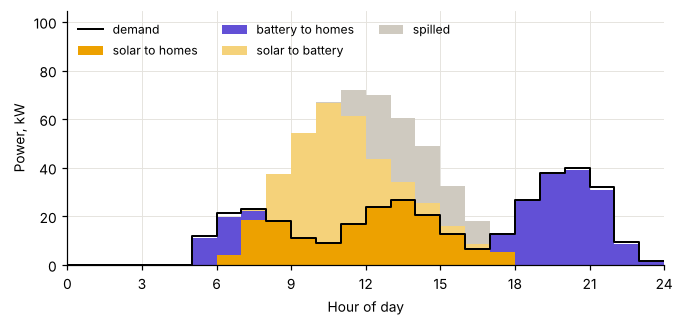

share of energy served that passes through the battery: 52%
share of solar output spilled: 23% | unserved: 2.0% of demand


In [13]:
def average_day(site):
    sz, b = DESIGNS[site, 1.0]
    st = {**sz, **sz["stages"][0]}
    st.pop("stages")
    c, res = CFG[site], RES[site]
    load = np.asarray(b(1), dtype=float)
    d = dispatch_year(load, np.asarray(res["ghi"]), np.asarray(res["tair"]), c, st,
                      Battery.from_cfg(c, st["battery_kwh"]), 1)
    pv_ac = _pv_dc(c, st, np.asarray(res["ghi"]), np.asarray(res["tair"]), 1) * c["bos"]["inverter_eff"]
    f = pd.DataFrame({"load": load, "solar to homes": d["pv_to_load"], "battery to homes": d["batt_to_load"],
                      "unserved": d["unmet"], "spilled": d["curtailed"] * c["bos"]["inverter_eff"], "pv_ac": pv_ac})
    f["solar to battery"] = (f.pv_ac - f["solar to homes"] - f.spilled).clip(lower=0)
    return f, f.groupby(np.arange(8760) % 24).mean()

f, day = average_day("rwanda")
fig, ax = plt.subplots(figsize=(7, 3))
h = np.arange(24)
ax.bar(h, day["solar to homes"], width=1, align="edge", color="#eda100", label="solar to homes")
ax.bar(h, day["battery to homes"], width=1, align="edge", bottom=day["solar to homes"], color="#6250d6", label="battery to homes")
top = day["solar to homes"] + day["battery to homes"]
ax.bar(h, day["solar to battery"], width=1, align="edge", bottom=top, color="#f5d27a", label="solar to battery")
ax.bar(h, day["spilled"], width=1, align="edge", bottom=top + day["solar to battery"], color="#cfcac0", label="spilled")
ax.step(np.r_[h, 24], np.r_[day["load"], day["load"].iloc[-1]], where="post", color="black", lw=1.3, label="demand")
ax.set_xlim(0, 24)
ax.set_ylim(0, 1.45 * (top + day["solar to battery"] + day["spilled"]).max())
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Power, kW")
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.show()
tot = f.sum()
print(f"share of energy served that passes through the battery: {100 * tot['battery to homes'] / (tot.load - tot.unserved):.0f}%")
print(f"share of solar output spilled: {100 * tot.spilled / tot.pv_ac:.0f}% | unserved: {100 * tot.unserved / tot.load:.1f}% of demand")

## 4. Cost, price and subsidy

With capital cost $C_0$, running cost $O_y$, battery replacement and second-stage cost $R_y+X_y$, energy served $E_y$ and real discount rate $r=12\%$:

$$\text{LCOE}=\frac{C_0+\sum_y(O_y+R_y+X_y)(1+r)^{-y}}{\sum_y E_y(1+r)^{-y}}.$$

Revenue applies each national tariff to monthly use, with 90% of bills collected. Three measures follow:

* the **operating subsidy** per home per year that brings the operator's net present value to zero, $S=-\text{NPV}/(N\cdot AF)$, with $N=300$ homes and annuity factor $AF$;
* the **extra subsidy per cooking home** when a share $a$ of homes cooks, $\Delta S_a=(S_a-S_0)/a$;
* the **cost of supplying cooking energy**, $c_{ck}=(PC_a-PC_0)/\sum_y E^{ck}_y(1+r)^{-y}$, where $PC$ is the numerator of the LCOE and $E^{ck}_y$ the cooking energy served.

In [14]:
AF = annuity_factor(CFG["rwanda"]["finance"]["discount_rate_real"], CFG["rwanda"]["finance"]["project_life_years"])
print(f"annuity factor AF = {AF:.3f}")
burden = []
for s in SITES:
    designs = {pen: DESIGNS[s, pen] for pen in (0.0, 0.5, 1.0)}
    burden.append(by_adoption(CFG[s], s, designs, RES[s], N_HOMES))
burden = pd.concat(burden)
saved_b = pd.read_csv(R / "burden.csv")
assert np.allclose(burden.opsub_usd_per_conn_year, saved_b.opsub_usd_per_conn_year), "subsidy differs from results/"
show = burden[["site", "penetration", "lcoe", "npv", "avg_price_paid", "opsub_usd_per_conn_year",
               "incremental_usd_per_cooking_hh_year", "incremental_cost_per_cooking_kwh"]].copy()
show.columns = ["site", "homes cooking", "LCOE $/kWh", "NPV $", "price paid $/kWh", "S $/home/yr",
                "extra S per cooking home $/yr", "cost of cooking energy $/kWh"]
show

annuity factor AF = 7.469


,site,homes cooking,LCOE $/kWh,NPV $,price paid $/kWh,S $/home/yr,extra S per cooking home $/yr,cost of cooking energy $/kWh
0,rwanda,0.0,2.205,-411288.027,0.061,183.544,NaN,NaN
1,rwanda,0.5,1.035,-567525.592,0.073,253.267,139.446,0.464
2,rwanda,1.0,0.807,-677320.029,0.129,302.267,118.723,0.466
0,kenya,0.0,1.387,-476161.890,0.094,212.498,NaN,NaN
1,kenya,0.5,0.888,-606700.194,0.100,270.748,116.501,0.421
2,kenya,1.0,0.737,-718964.784,0.128,320.854,108.356,0.433


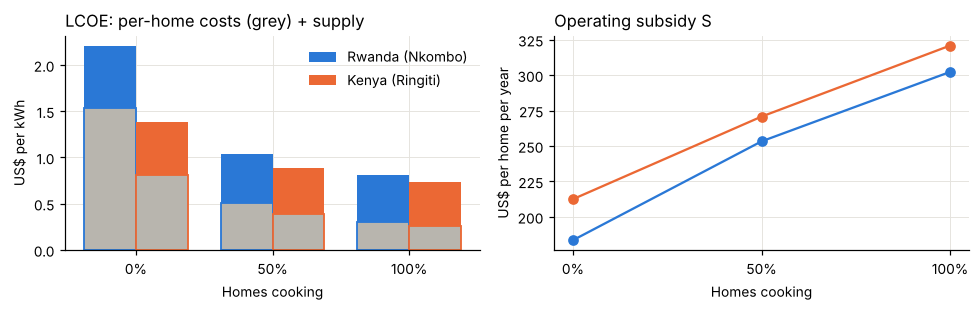

In [15]:
cvp = pd.read_csv(R / "cost_vs_price.csv")
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 2.9))
x, w = np.arange(3), 0.38
for k, s in enumerate(SITES):
    g = cvp[cvp.site == s].sort_values("penetration")
    a.bar(x + (k - 0.5) * w, g.per_connection_fixed, w, color="#b8b5ae", edgecolor=COL[s], lw=1.2)
    a.bar(x + (k - 0.5) * w, g.supply, w, bottom=g.per_connection_fixed, color=COL[s], label=NAME[s])
    gb = burden[burden.site == s]
    b.plot(x, gb.opsub_usd_per_conn_year, "o-", color=COL[s], label=NAME[s])
a.set_xticks(x, ["0%", "50%", "100%"])
a.set_xlabel("Homes cooking")
a.set_ylabel("US$ per kWh")
a.set_title("LCOE: per-home costs (grey) + supply", loc="left")
a.legend()
b.set_xticks(x, ["0%", "50%", "100%"])
b.set_xlabel("Homes cooking")
b.set_ylabel("US$ per home per year")
b.set_title("Operating subsidy S", loc="left")
plt.tight_layout()
plt.show()

Cooking makes the system **cheaper per kWh** but **more expensive to support**. The per-home costs (US\$400 to connect, US\$60 a year to serve) do not change with use, so spreading them over far more energy lowers the LCOE. Yet each extra kWh of cooking costs more to supply than the operator collects for it at the national tariff, so the loss grows.

### 4.1 Worked example: where the extra subsidy comes from (Rwanda)

In [16]:
b0 = burden[(burden.site == "rwanda") & (burden.penetration == 0)].iloc[0]
b1 = burden[(burden.site == "rwanda") & (burden.penetration == 1)].iloc[0]
d_cost = b1.cost_pv - b0.cost_pv                         # extra present value of all costs
c_ck = d_cost / b1.cooking_pv_kwh                        # cost of supplying cooking energy
extra_cost_year = d_cost / AF / N_HOMES                  # spread evenly over 20 years, per home
extra_revenue_year = extra_cost_year - b1.incremental_usd_per_cooking_hh_year
print(f"present value of costs: {b0.cost_pv:,.0f} -> {b1.cost_pv:,.0f} US$ (difference {d_cost:,.0f})")
print(f"cooking energy served, present value: {b1.cooking_pv_kwh:,.0f} kWh")
print(f"cost of supplying cooking energy  c_ck = {d_cost:,.0f} / {b1.cooking_pv_kwh:,.0f} = {c_ck:.3f} US$/kWh")
print(f"extra cost per cooking home per year   = {extra_cost_year:.0f} US$")
print(f"extra revenue collected per home/year  = {extra_revenue_year:.0f} US$ "
      f"({extra_revenue_year / b1.cooking_kwh_per_cooking_hh_year:.3f} US$ per kWh of cooking)")
print(f"extra subsidy per cooking home          = {b1.incremental_usd_per_cooking_hh_year:.0f} US$ a year")

present value of costs: 421,781 -> 791,562 US$ (difference 369,781)
cooking energy served, present value: 793,904 kWh
cost of supplying cooking energy  c_ck = 369,781 / 793,904 = 0.466 US$/kWh
extra cost per cooking home per year   = 165 US$
extra revenue collected per home/year  = 46 US$ (0.127 US$ per kWh of cooking)
extra subsidy per cooking home          = 119 US$ a year


### 4.2 Tariff scenarios and household bills

The same full-adoption village under higher, site-specific tariffs. Higher prices shrink the subsidy but move the burden onto household bills.

In [17]:
T, NUM = build_all(R)
tariffs = {"national": "national tariff", "oloika": "KES 40/kWh (Oloika)", "amda": "US$0.56/kWh (AMDA model)",
           "breakeven": "break-even tariff"}
rows = []
for s in SITES:
    for k, lab in tariffs.items():
        rows.append({"site": s, "tariff": lab, "avg price $/kWh": NUM[f"ts_price_{k}_{s}"],
                     "S $/home/yr": NUM[f"ts_opsub_{k}_{s}"], "extra S per cooking home $/yr": NUM[f"ts_incremental_{k}_{s}"],
                     "bill added by cooking $/month": NUM[f"ts_cooking_bill_{k}_{s}"]})
display(pd.DataFrame(rows))

be = pd.read_csv(R / "bill_example.csv")
be[["site", "currency", "kwh_no_cooking", "kwh_cooking", "bill_no_cooking_local", "bill_cooking_local",
    "energy_ratio", "bill_ratio", "price_ratio"]]

,site,tariff,avg price $/kWh,S $/home/yr,extra S per cooking home $/yr,bill added by cooking $/month
0,rwanda,national tariff,0.130,302.267,118.723,4.395
1,rwanda,KES 40/kWh (Oloika),0.310,231.047,66.633,9.437
2,rwanda,US$0.56/kWh (AMDA model),0.560,132.551,-12.665,17.043
3,rwanda,break-even tariff,0.896,0.000,-119.371,27.280
4,kenya,national tariff,0.128,320.854,108.356,4.304
5,kenya,KES 40/kWh (Oloika),0.310,236.235,55.456,9.437
6,kenya,US$0.56/kWh (AMDA model),0.560,120.144,-23.928,17.043
7,kenya,break-even tariff,0.819,0.000,-106.087,24.914


,site,currency,kwh_no_cooking,kwh_cooking,bill_no_cooking_local,bill_cooking_local,energy_ratio,bill_ratio,price_ratio
0,rwanda,RWF,6.343,36.777,564.546,6980.959,5.798,12.366,2.133
1,kenya,KES,12.162,42.596,147.648,702.837,3.502,4.760,1.359


## 5. Household-level analytics

RAMP gives the village load but not each home's use. For billing, each home's appliance set is drawn from the ownership shares and scaled so that the village total matches RAMP; each cooking home adds its own simulated meals.

Because tariffs are not linear, **the bill of the average home is not the average bill**. With $e_{im}$ the use of home $i$ in month $m$ and $\bar e_m$ the village mean, the error from billing the average home is

$$\beta=\frac{\sum_m N\,B(\bar e_m)}{\sum_m\sum_i B(e_{im})}-1.$$

,site,homes cooking,mean kWh/month,p10,p90,"home-months above first block, %","billing error beta, %"
0,rwanda,0%,6.34,0.74,14.58,3.50,-12.39
1,rwanda,100%,36.78,31.24,44.44,99.97,-0.37
2,kenya,0%,12.16,0.86,26.69,7.64,-10.04
3,kenya,100%,42.60,31.20,57.26,90.42,1.57


         10%   50%   90%
site                    
kenya   1.18  1.36  1.36
rwanda  1.89  2.06  2.32


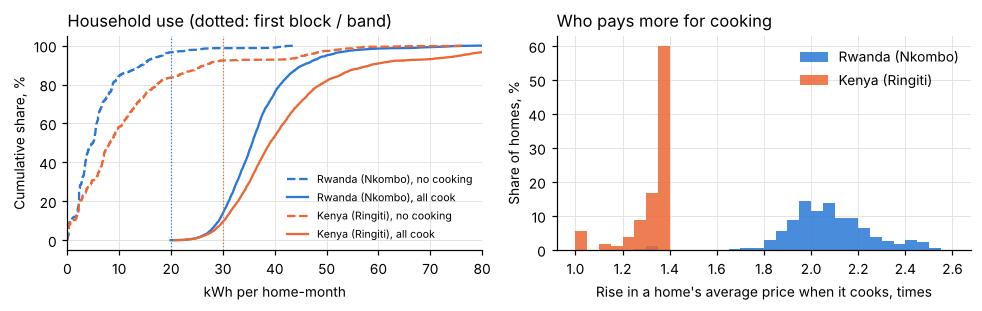

In [18]:
HH, rows, factors = {}, [], []
for s in SITES:
    t = CFG[s]["tariff"]
    for pen in (0.0, 1.0):
        hh = household_monthly(CFG[s], N_HOMES, pen, 0.0, SEED, 1)      # (homes, 12) kWh
        HH[s, pen] = hh
        rev_each = sum(bill(k, t) for k in hh.ravel())
        rev_mean = sum(N_HOMES * bill(k, t) for k in hh.mean(axis=0))
        monthly = hh.sum(axis=1) / 12
        rows.append({"site": s, "homes cooking": f"{pen:.0%}", "mean kWh/month": hh.mean(),
                     "p10": np.percentile(monthly, 10), "p90": np.percentile(monthly, 90),
                     "home-months above first block, %": 100 * (hh > t["bands"][0][0]).mean(),
                     "billing error beta, %": 100 * (rev_mean / rev_each - 1)})
    rate = lambda m, t=t: sum(bill(k, t) for k in m) / max(m.sum(), 1e-12)
    for a_, b_ in zip(HH[s, 0.0], HH[s, 1.0]):
        if a_.sum() > 0:
            factors.append({"site": s, "factor": rate(b_) / rate(a_)})
hb = pd.DataFrame(rows)
display(hb.round(2))
factors = pd.DataFrame(factors)
print(factors.groupby("site").factor.describe(percentiles=[0.1, 0.5, 0.9])[["10%", "50%", "90%"]].round(2))

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 2.9))
for s in SITES:
    for pen, ls in ((0.0, "--"), (1.0, "-")):
        x = np.sort(HH[s, pen].ravel())
        a.plot(x, 100 * np.arange(1, len(x) + 1) / len(x), color=COL[s], ls=ls,
               label=f"{NAME[s]}, {'all cook' if pen else 'no cooking'}")
    b.hist(factors[factors.site == s].factor, bins=np.arange(1.0, 2.65, 0.05), color=COL[s], alpha=0.85,
           weights=np.full((factors.site == s).sum(), 100 / (factors.site == s).sum()), label=NAME[s])
a.axvline(20, color=COL["rwanda"], ls=":", lw=0.8)
a.axvline(30, color=COL["kenya"], ls=":", lw=0.8)
a.set_xlim(0, 80)
a.set_xlabel("kWh per home-month")
a.set_ylabel("Cumulative share, %")
a.set_title("Household use (dotted: first block / band)", loc="left")
a.legend(fontsize=7)
b.set_xlabel("Rise in a home's average price when it cooks, times")
b.set_ylabel("Share of homes, %")
b.set_title("Who pays more for cooking", loc="left")
b.legend()
plt.tight_layout()
plt.show()

Without cooking, use is spread widely and few homes leave the cheap first block, so billing the average home would understate revenue by about 10 to 12%. With cooking nearly every home sits above the first block and the error almost vanishes. In Rwanda every home's average price roughly doubles when it starts cooking; in Kenya most homes see the same 1.36-fold rise because crossing 30 kWh moves the whole month to the next band.

## 6. Weather-year analytics

Each system is sized on its site's hardest year. Here we run that design, and a cheaper design sized on the median year, against all 20 weather years.

In [19]:
t0 = time.time()
WR = []
for s in SITES:
    c = CFG[s]
    sz, b = DESIGNS[s, 1.0]
    kw = {"pv_range": tuple(c["sizing"]["pv_range"]), "batt_range": tuple(c["sizing"]["battery_range"])}
    med, _ = size_design(c, b, YEARS[s][MEDIAN_YEAR[s]], N_HOMES, **kw)
    for lab, design in (("hardest year", sz), ("median year", med)):
        d = by_weather_year(c, design, b, YEARS[s])
        d["site"], d["sizing"] = s, lab
        d["design"] = f"{design['stages'][0]['pv_kw']:.0f} kW / {design['stages'][0]['battery_kwh']:.0f} kWh"
        WR.append(d)
WR = pd.concat(WR)
print(f"ran 2 designs x 20 weather years x 2 sites in {time.time() - t0:.0f} s")
summary = WR.groupby(["site", "sizing", "design"]).agg(
    years_above_5pct=("worst_year_unmet_fraction", lambda u: int((u > 0.05).sum())),
    worst_unserved_pct=("worst_year_unmet_fraction", lambda u: 100 * u.max()),
    lcoe_min=("lcoe", "min"), lcoe_max=("lcoe", "max"))
summary

ran 2 designs x 20 weather years x 2 sites in 4 s


years_above_5pct  worst_unserved_pct  lcoe_min  lcoe_max
site   sizing       design                                                                    
kenya  hardest year 145 kW / 400 kWh                 0               4.993     0.724     0.737
       median year  135 kW / 400 kWh                 4               6.323     0.710     0.728
rwanda hardest year 135 kW / 340 kWh                 0               4.941     0.794     0.807
       median year  130 kW / 340 kWh                 7               6.429     0.786     0.800

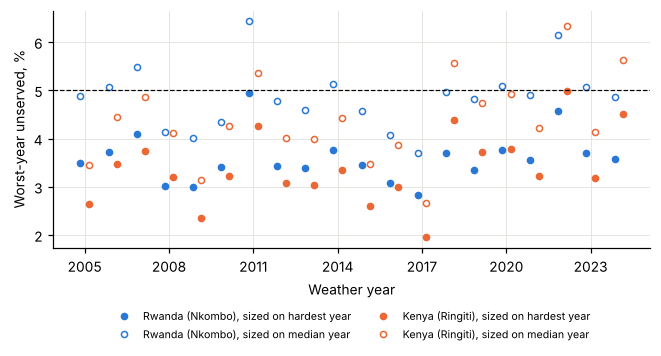

In [20]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for s in SITES:
    for lab, mk in (("hardest year", "o"), ("median year", "o")):
        g = WR[(WR.site == s) & (WR.sizing == lab)]
        off = -0.15 if s == "rwanda" else 0.15
        ax.plot(g.weather_year + off, 100 * g.worst_year_unmet_fraction, mk, ms=4,
                mfc=COL[s] if lab == "hardest year" else "white", mec=COL[s], ls="none",
                label=f"{NAME[s]}, sized on {lab}")
ax.axhline(5, color="black", ls="--", lw=0.8)
ax.set_xticks(range(2005, 2025, 3))
ax.set_xlabel("Weather year")
ax.set_ylabel("Worst-year unserved, %")
ax.legend(ncol=2, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.show()

### 6.1 Which property of a weather year causes shortfalls?

We screen seven features of the daily irradiance record against the shortfall of the median-year design. With 20 years per site, a correlation above about 0.44 in size is significant at the 5% level.

,Rwanda (Nkombo),Kenya (Ringiti)
annual sum,-0.71,-0.96
darkest day,-0.34,-0.25
darkest 3 days,-0.64,0.16
darkest 5 days,-0.65,-0.12
darkest 10 days,-0.45,-0.66
days below 60% of median,0.47,0.97
10th-percentile day,-0.89,-0.96


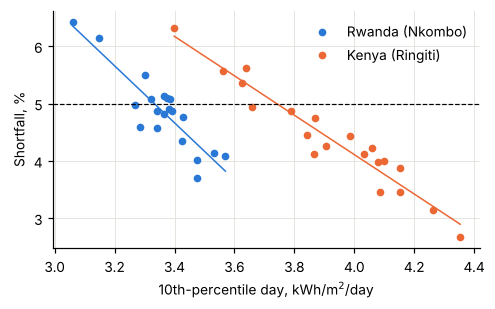

In [21]:
feat_rows = []
for s in SITES:
    m = WR[(WR.site == s) & (WR.sizing == "median year")].set_index("weather_year").worst_year_unmet_fraction
    for y, r in sorted(YEARS[s].items()):
        d = np.asarray(r["ghi"])[:8760].reshape(365, 24).sum(1) / 1000         # kWh/m2 per day
        roll = pd.Series(d)
        feat_rows.append({"site": s, "year": y, "annual sum": d.sum(), "darkest day": d.min(),
                          "darkest 3 days": roll.rolling(3).mean().min(),
                          "darkest 5 days": roll.rolling(5).mean().min(),
                          "darkest 10 days": roll.rolling(10).mean().min(),
                          "days below 60% of median": (d < 0.6 * np.median(d)).sum(),
                          "10th-percentile day": np.percentile(d, 10), "shortfall": m.loc[y]})
WF = pd.DataFrame(feat_rows)
corr = pd.DataFrame({s: {c: WF[WF.site == s][c].corr(WF[WF.site == s].shortfall)
                         for c in WF.columns[2:-1]} for s in SITES})
display(corr.round(2).rename(columns=NAME))

fig, ax = plt.subplots(figsize=(5, 2.8))
for s in SITES:
    g = WF[WF.site == s]
    ax.plot(g["10th-percentile day"], 100 * g.shortfall, "o", ms=4, color=COL[s], label=NAME[s])
    k = np.polyfit(g["10th-percentile day"], 100 * g.shortfall, 1)
    xx = np.linspace(g["10th-percentile day"].min(), g["10th-percentile day"].max(), 10)
    ax.plot(xx, np.polyval(k, xx), color=COL[s], lw=1)
ax.axhline(5, color="black", ls="--", lw=0.8)
ax.set_xlabel("10th-percentile day, kWh/m$^2$/day")
ax.set_ylabel("Shortfall, %")
ax.legend()
plt.show()

The annual total is a good guide in Kenya but a weak one in Rwanda, where the hardest year (2011) is not the darkest (2022). The darkest single day or the darkest few days predict little. The irradiance of a typical poor day (the 10th-percentile day) predicts shortfalls best at both sites: with a battery that covers the evening, shortfalls build up over many poor days rather than in one long dark spell. With 20 years and seven features, treat this ranking as indicative.

## 7. Uncertainty

### 7.1 Random household behaviour

Results that depend on which homes own what and when they cook were repeated with 24 random seeds (`python src/pipeline.py ensemble` re-runs them; about ten minutes). The 95% interval of the mean is $\bar x\pm t_{0.975,K-1}\,s/\sqrt{K}$.

In [22]:
e = pd.read_csv(R / "ensemble_seeds.csv")
cols = {"lcoe_flat_full": "LCOE, all cook", "incremental_usd_per_cooking_hh_year": "extra S per cooking home",
        "avoided_battery_pct_phi50": "battery saved, half of supper moved, %",
        "peak_cooking_increase_pct_phi50": "change in cooking peak, half moved, %"}
rows = []
for s in SITES:
    g = e[e.site == s]
    t = stats.t.ppf(0.975, len(g) - 1)
    for c, lab in cols.items():
        x = g[c]
        rows.append({"site": s, "quantity": lab, "seeds": len(x), "mean": x.mean(),
                     "95% CI of mean +/-": t * x.std() / np.sqrt(len(x)),
                     "single-run min": x.min(), "single-run max": x.max()})
pd.DataFrame(rows).round(3)

,site,quantity,seeds,mean,95% CI of mean +/-,single-run min,single-run max
0,rwanda,"LCOE, all cook",24,0.809,0.001,0.805,0.815
1,rwanda,extra S per cooking home,24,119.930,0.725,117.407,122.805
2,rwanda,"battery saved, half of supper moved, %",24,14.677,1.302,11.429,24.324
3,rwanda,"change in cooking peak, half moved, %",24,32.018,2.769,19.794,42.050
4,kenya,"LCOE, all cook",24,0.736,0.001,0.734,0.740
5,kenya,extra S per cooking home,24,109.803,0.303,108.347,111.103
6,kenya,"battery saved, half of supper moved, %",24,22.874,0.408,20.930,23.810
7,kenya,"change in cooking peak, half moved, %",24,32.018,2.769,19.794,42.050


With 300 homes, random behaviour barely moves the subsidy result. Single runs are much less reliable for effects that depend on discrete battery steps, such as the battery saved by moving supper cooking into the afternoon; there the 24-run mean is needed.

### 7.2 Cost inputs, data choices and system design

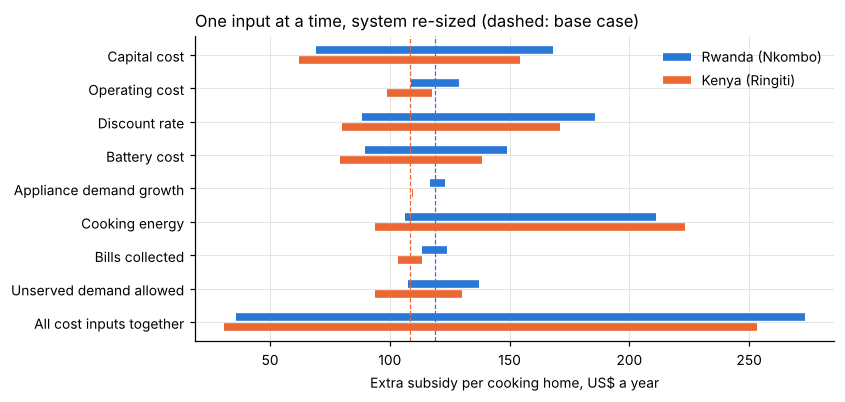

,Rwanda (Nkombo),Kenya (Ringiti)
Kenyan survey question (roster instead of core),NaN,115.0
Ownership scaled to island census districts,120.0,109.0
"System design, lowest",92.0,86.0
"System design, highest",131.0,121.0


base case: {'rwanda': 119, 'kenya': 108}


In [23]:
sens = pd.read_csv(R / "sensitivity.csv")
struct = pd.read_csv(R / "structural.csv")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
params_ = [p for p in sens.parameter.unique() if p != "Base case"]
y = np.arange(len(params_))[::-1]
for k, s in enumerate(SITES):
    g = sens[sens.site == s]
    base = g[g.parameter == "Base case"].incremental_usd_per_cooking_hh_year.iloc[0]
    for yy, p in zip(y, params_):
        v = g[g.parameter == p].incremental_usd_per_cooking_hh_year
        ax.plot([v.min(), v.max()], [yy + (0.15 if k == 0 else -0.15)] * 2, color=COL[s], lw=5,
                solid_capstyle="butt", label=NAME[s] if yy == y[0] else None)
    ax.axvline(base, color=COL[s], ls="--", lw=0.8)
ax.set_yticks(y, params_)
ax.set_xlabel("Extra subsidy per cooking home, US$ a year")
ax.set_title("One input at a time, system re-sized (dashed: base case)", loc="left")
ax.legend(loc="upper right")
plt.show()

alt = pd.DataFrame({
    "Kenyan survey question (roster instead of core)": [np.nan, NUM["kenya_incremental_usd_per_cooking_hh_year_m3"]],
    "Ownership scaled to island census districts": [NUM["site_incremental_usd_per_cooking_hh_year_island_rwanda"],
                                                    NUM["site_incremental_usd_per_cooking_hh_year_island_kenya"]],
    "System design, lowest": [struct[struct.site == s].incremental_usd_per_cooking_hh_year.min() for s in SITES],
    "System design, highest": [struct[struct.site == s].incremental_usd_per_cooking_hh_year.max() for s in SITES],
}, index=[NAME[s] for s in SITES]).T
display(alt.round(0))
print("base case:", {s: round(burden[(burden.site == s) & (burden.penetration == 1)].incremental_usd_per_cooking_hh_year.iloc[0])
                     for s in SITES})

The ranking is clear: random behaviour moves the extra subsidy by a few dollars, data choices by a few more, system design by tens of dollars and cost inputs by hundreds. In every case, cooking lowers the LCOE and adds to the subsidy at the national tariff.

## 8. Headline numbers

All numbers below are read from `results/` by the same code that fills the manuscript tables.

In [24]:
keys = {
    "LCOE, no cooking (US$/kWh)": "lcoe_zero_{s}", "LCOE, all cook (US$/kWh)": "lcoe_full_{s}",
    "LCOE fall (%)": "lcoe_reduction_pct_{s}", "operator's loss grows by (%)": "burden_loss_increase_pct_{s}",
    "S, no cooking (US$/home/yr)": "burden_opsub_0_{s}", "S, all cook (US$/home/yr)": "burden_opsub_100_{s}",
    "extra S per cooking home (US$/yr)": "burden_incremental_100_{s}",
    "same, mean of 24 seeds": "ens_incremental_usd_per_cooking_hh_year_{s}",
    "cost of cooking energy (US$/kWh)": "burden_cooking_cost_per_kwh_100_{s}",
    "break-even tariff (US$/kWh)": "breakeven_tariff_{s}",
    "extra S, all cost inputs low (US$/yr)": "sens_incremental_all_low_{s}",
    "extra S, all cost inputs high (US$/yr)": "sens_incremental_all_high_{s}",
    "median-year sizing: years above 5% unserved": "weather_median_weather_years_breaching_{s}",
}
pd.DataFrame({NAME[s]: {lab: NUM[k.format(s=s)] for lab, k in keys.items()} for s in SITES}).round(2)

,Rwanda (Nkombo),Kenya (Ringiti)
"LCOE, no cooking (US$/kWh)",2.21,1.39
"LCOE, all cook (US$/kWh)",0.81,0.74
LCOE fall (%),63.42,46.88
operator's loss grows by (%),64.68,50.99
"S, no cooking (US$/home/yr)",183.54,212.50
"S, all cook (US$/home/yr)",302.27,320.85
extra S per cooking home (US$/yr),118.72,108.36
"same, mean of 24 seeds",119.93,109.80
cost of cooking energy (US$/kWh),0.47,0.43
break-even tariff (US$/kWh),0.90,0.82


## How to reproduce everything

| What | Command | Time |
|---|---|---|
| Download hourly weather (network) | `python src/pipeline.py resource` | about 80 s |
| Re-derive survey aggregates (needs licensed microdata in `data/raw/`) | `python src/pipeline.py mtf` | about 1 min |
| Every result in `results/` | `python src/pipeline.py all` | about 30 min |
| Automated tests | `python -m pytest -q` | a few minutes |

**Limitations to keep in mind.** The model has no price response: the share of homes cooking is set, not predicted, so full adoption is an upper bound. The Kenyan survey is older than the Rwandan one, demand uses national rural averages, and the model villages contain homes only. Appliance sets are drawn independently for each appliance, so the spread between homes and the billing error are lower bounds.